# 09 — SHAP Analysis untuk GlySense Stacking Ensemble

**Tujuan:** menjelaskan bagaimana fitur gaya hidup berkontribusi terhadap prediksi model Random Forest, XGBoost, dan Stacking Ensemble.

Model yang dianalisis:
- Random Forest (`random_forest_final.joblib`)
- XGBoost (`xgboost_final.joblib`)
- Logistic Regression meta-learner (`meta_logistic_regression.joblib`)

Analisis utama untuk interpretasi model akhir menggunakan **model-agnostic SHAP** pada probabilitas kelas Prediabetes dari keseluruhan Stacking Ensemble.

> Jalankan notebook dari folder `glysense_backend/` agar seluruh path relatif sesuai. Notebook ini hanya membaca model dan data; tidak melatih ulang atau menimpa artifact model.

## 1. Persiapan library

Jika SHAP belum terpasang di environment, jalankan perintah instalasi pada sel berikut. Setelah instalasi, restart kernel jika diminta.

In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

print(os.getcwd())

d:\Tugas Akhir\Aplikasi Diabetes\glysense_backend


In [2]:
# Jalankan hanya jika library belum tersedia
# %pip install shap

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.utils.validation import check_is_fitted

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


## 2. Memuat dataset dan artifact model

Gunakan `train_final.csv` untuk mengambil sampel data latar belakang dan data yang akan dijelaskan. `test_final_locked.csv` sengaja tidak digunakan pada tahap interpretasi dan pengembangan ini agar tetap terkunci untuk evaluasi final.

In [3]:
TRAIN_PATH = "data/final_split/train_final.csv"
ARTIFACT_DIR = "artifacts"

RF_PATH = os.path.join(ARTIFACT_DIR, "random_forest_final.joblib")
XGB_PATH = os.path.join(ARTIFACT_DIR, "xgboost_final.joblib")
META_PATH = os.path.join(ARTIFACT_DIR, "meta_logistic_regression.joblib")
FEATURE_PATH = os.path.join(ARTIFACT_DIR, "feature_names.joblib")

required_paths = [TRAIN_PATH, RF_PATH, XGB_PATH, META_PATH, FEATURE_PATH]
missing_paths = [path for path in required_paths if not os.path.exists(path)]
if missing_paths:
    raise FileNotFoundError(
        "File berikut tidak ditemukan. Pastikan notebook dijalankan dari "
        "folder glysense_backend:\n" + "\n".join(missing_paths)
    )

df_train = pd.read_csv(TRAIN_PATH)
feature_names = joblib.load(FEATURE_PATH)

X_train = df_train.drop(columns=["Diabetes_012"])
y_train = df_train["Diabetes_012"].astype(int)

# Samakan urutan fitur dengan urutan yang digunakan saat model dilatih
if set(X_train.columns) != set(feature_names):
    raise ValueError("Kolom dataset tidak sama dengan feature_names.joblib.")

X_train = X_train[feature_names]

rf_model = joblib.load(RF_PATH)
xgb_model = joblib.load(XGB_PATH)
meta_model = joblib.load(META_PATH)

check_is_fitted(rf_model)
check_is_fitted(xgb_model)
check_is_fitted(meta_model)

print("Ukuran data training:", X_train.shape)
print("Jumlah fitur:", len(feature_names))
print("Distribusi target:")
print(y_train.value_counts().sort_index())
print("\nUrutan kelas RF:", rf_model.classes_)
print("Urutan kelas XGBoost:", xgb_model.classes_)
print("Urutan kelas meta-learner:", meta_model.classes_)

Ukuran data training: (202944, 21)
Jumlah fitur: 21
Distribusi target:
Diabetes_012
0    170962
1      3705
2     28277
Name: count, dtype: int64

Urutan kelas RF: [0 1 2]
Urutan kelas XGBoost: [0 1 2]
Urutan kelas meta-learner: [0 1 2]


## 3. Menyiapkan fungsi prediksi Stacking Ensemble

Urutan enam kolom input meta-learner harus sama dengan proses training: tiga probabilitas Random Forest terlebih dahulu, kemudian tiga probabilitas XGBoost.

Fungsi di bawah menghasilkan **probabilitas**, bukan label kelas hasil threshold. SHAP lebih tepat digunakan untuk menjelaskan perubahan nilai probabilitas. Threshold Prediabetes (misalnya 0.39) merupakan aturan keputusan setelah probabilitas diperoleh; threshold tidak diterapkan di dalam fungsi penjelasan ini.

Pastikan implementasi ini sama dengan alur prediksi pada `model/predict.py`.

In [4]:
def stacking_predict_proba(X):
    """Menghasilkan probabilitas kelas dari keseluruhan stacking model."""
    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(X, columns=feature_names)

    X = X.loc[:, feature_names]

    rf_proba = rf_model.predict_proba(X)
    xgb_proba = xgb_model.predict_proba(X)

    meta_features = np.hstack([rf_proba, xgb_proba])
    return meta_model.predict_proba(meta_features)


def stacking_predict_prediabetes_probability(X):
    """Probabilitas kelas 1 (Prediabetes) dari stacking ensemble."""
    meta_classes = list(meta_model.classes_)
    if 1 not in meta_classes:
        raise ValueError("Meta-learner tidak memiliki kelas 1 (Prediabetes).")
    class_index = meta_classes.index(1)
    return stacking_predict_proba(X)[:, class_index]


# Pemeriksaan awal: bentuk output dan rentang probabilitas
sample_check = X_train.iloc[:5]
sample_probabilities = stacking_predict_proba(sample_check)

print("Bentuk probabilitas:", sample_probabilities.shape)
print("Jumlah probabilitas per baris:", sample_probabilities.sum(axis=1))
print("Probabilitas Prediabetes:", stacking_predict_prediabetes_probability(sample_check))

Bentuk probabilitas: (5, 3)
Jumlah probabilitas per baris: [1. 1. 1. 1. 1.]
Probabilitas Prediabetes: [0.4036421  0.07725099 0.38856433 0.41176281 0.43619493]


## 4. Menentukan sampel SHAP

Agar proses model-agnostic SHAP tidak terlalu berat, gunakan sampel acak dari data training:
- **Background:** 30 baris untuk mewakili kondisi data acuan.
- **Data yang dijelaskan:** 50 baris untuk analisis awal.

Ukuran ini dapat ditingkatkan setelah notebook berhasil dijalankan dan waktu komputasi diketahui. Sampel acak dibuat dengan `random_state=42` agar dapat direproduksi.

In [5]:
BACKGROUND_SIZE = 100
EXPLAIN_PER_CLASS = 100

background = X_train.sample(n=BACKGROUND_SIZE, random_state=RANDOM_STATE)
remaining = df_train.drop(index=background.index)

X_explain = pd.concat([
    remaining[remaining["Diabetes_012"] == k].sample(n=EXPLAIN_PER_CLASS, random_state=RANDOM_STATE)
    for k in [0, 1, 2]
]).drop(columns="Diabetes_012")[feature_names]

print("Background:", background.shape)
print("Data yang dijelaskan:", X_explain.shape)

Background: (100, 21)
Data yang dijelaskan: (300, 21)


## 5. Tree SHAP — Random Forest

TreeExplainer digunakan untuk menjelaskan base learner Random Forest. Karena target memiliki tiga kelas, SHAP dapat menghasilkan nilai untuk setiap kelas.

Plot pertama menampilkan ringkasan pengaruh fitur untuk kelas Prediabetes (kelas 1), jika format output SHAP dari versi library mendukung pemilihan kelas seperti pada kode berikut.

In [6]:
rf_explainer = shap.TreeExplainer(rf_model)
rf_shap_values_raw = rf_explainer.shap_values(X_explain)

print("Tipe output SHAP RF:", type(rf_shap_values_raw))
if isinstance(rf_shap_values_raw, list):
    print("Jumlah output kelas:", len(rf_shap_values_raw))
    rf_shap_prediabetes = rf_shap_values_raw[1]
else:
    rf_values_array = np.asarray(rf_shap_values_raw)
    # Beberapa versi SHAP mengembalikan (samples, features, classes)
    if rf_values_array.ndim == 3 and rf_values_array.shape[-1] == 3:
        rf_shap_prediabetes = rf_values_array[:, :, 1]
    else:
        raise ValueError(
            f"Format SHAP RF tidak dikenali: {rf_values_array.shape}. "
            "Periksa versi SHAP dan bentuk output."
        )

print("Bentuk SHAP RF kelas Prediabetes:", np.asarray(rf_shap_prediabetes).shape)

Tipe output SHAP RF: <class 'numpy.ndarray'>
Bentuk SHAP RF kelas Prediabetes: (300, 21)


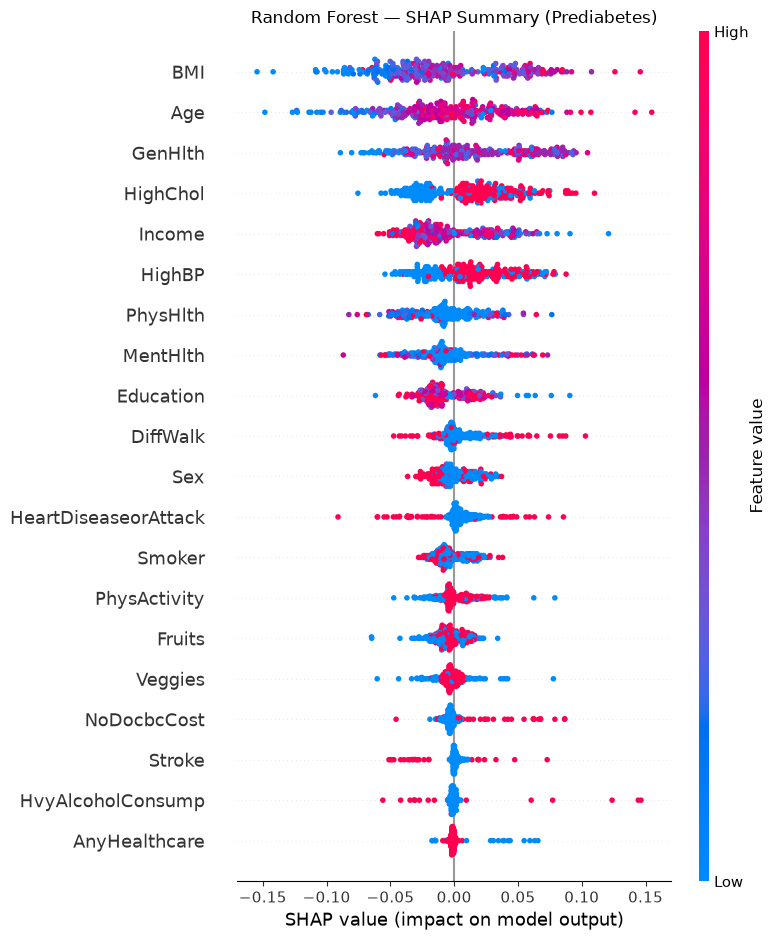

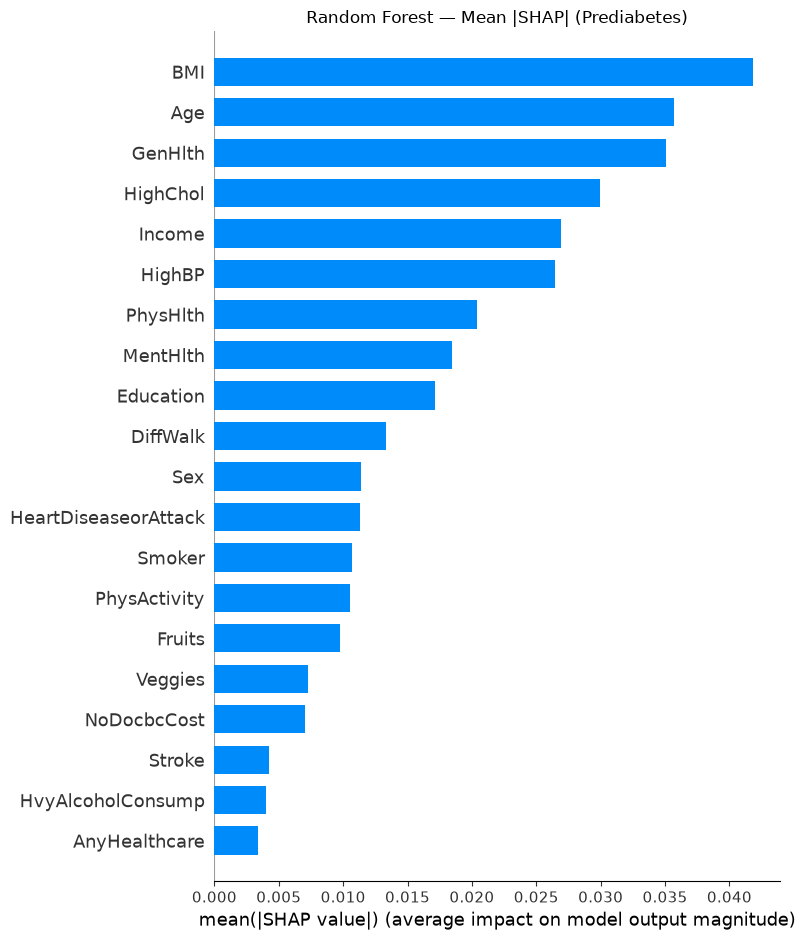

In [7]:
# Summary plot: arah dan sebaran kontribusi fitur pada RF
shap.summary_plot(
    rf_shap_prediabetes,
    X_explain,
    feature_names=feature_names,
    show=False
)
plt.title("Random Forest — SHAP Summary (Prediabetes)")
plt.tight_layout()
plt.show()

# Bar plot: rata-rata nilai absolut SHAP untuk RF
shap.summary_plot(
    rf_shap_prediabetes,
    X_explain,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)
plt.title("Random Forest — Mean |SHAP| (Prediabetes)")
plt.tight_layout()
plt.show()

## 6. Tree SHAP — XGBoost

Analisis yang sama dilakukan pada XGBoost. Hasilnya menjelaskan kontribusi fitur pada base learner XGBoost, bukan kontribusi final Stacking Ensemble.

In [8]:
xgb_explainer = shap.TreeExplainer(xgb_model)
xgb_shap_values_raw = xgb_explainer.shap_values(X_explain)

print("Tipe output SHAP XGBoost:", type(xgb_shap_values_raw))
if isinstance(xgb_shap_values_raw, list):
    print("Jumlah output kelas:", len(xgb_shap_values_raw))
    xgb_shap_prediabetes = xgb_shap_values_raw[1]
else:
    xgb_values_array = np.asarray(xgb_shap_values_raw)
    if xgb_values_array.ndim == 3 and xgb_values_array.shape[-1] == 3:
        xgb_shap_prediabetes = xgb_values_array[:, :, 1]
    else:
        raise ValueError(
            f"Format SHAP XGBoost tidak dikenali: {xgb_values_array.shape}. "
            "Periksa versi SHAP dan bentuk output."
        )

print("Bentuk SHAP XGBoost kelas Prediabetes:", np.asarray(xgb_shap_prediabetes).shape)

Tipe output SHAP XGBoost: <class 'numpy.ndarray'>
Bentuk SHAP XGBoost kelas Prediabetes: (300, 21)


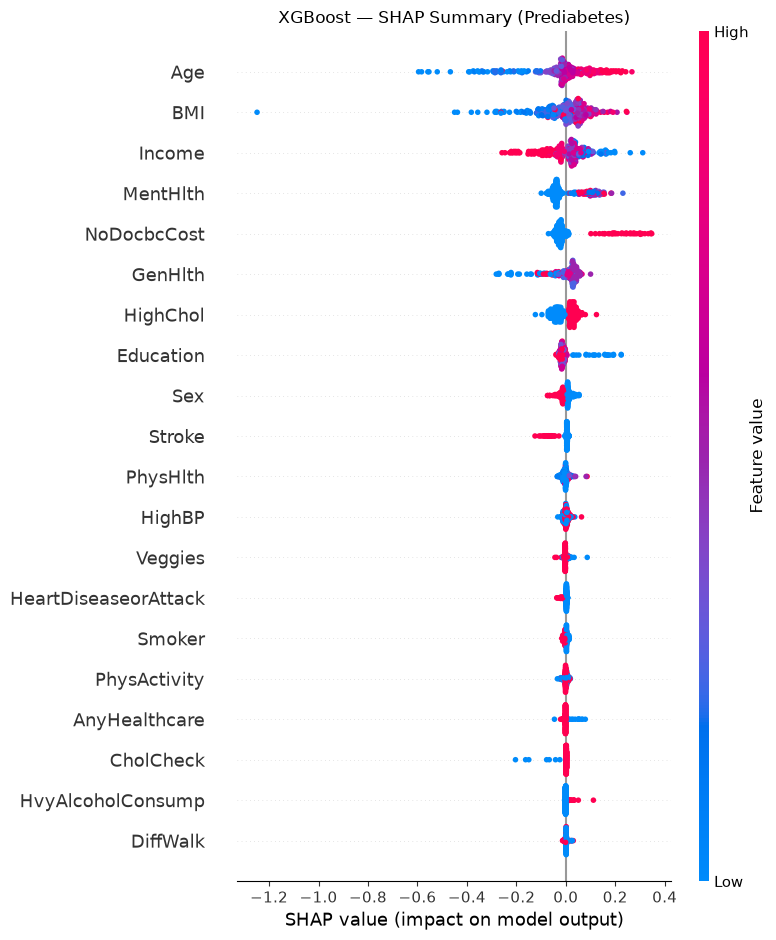

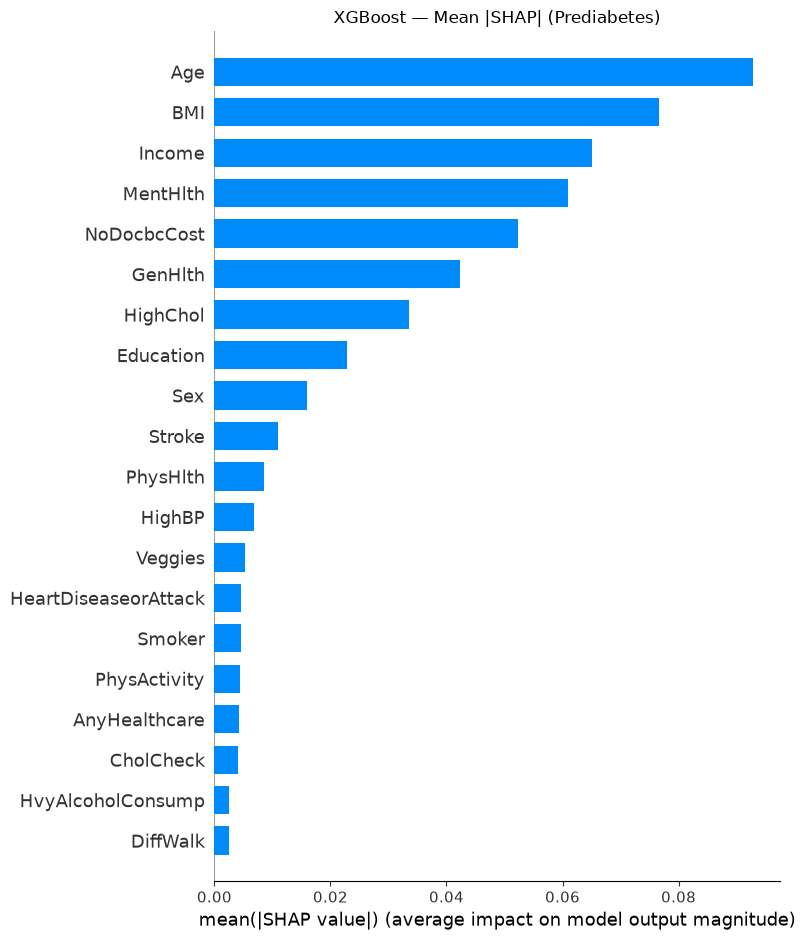

In [9]:
shap.summary_plot(
    xgb_shap_prediabetes,
    X_explain,
    feature_names=feature_names,
    show=False
)
plt.title("XGBoost — SHAP Summary (Prediabetes)")
plt.tight_layout()
plt.show()

shap.summary_plot(
    xgb_shap_prediabetes,
    X_explain,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)
plt.title("XGBoost — Mean |SHAP| (Prediabetes)")
plt.tight_layout()
plt.show()

## 7. SHAP model-agnostic — keseluruhan Stacking Ensemble

Ini adalah analisis utama untuk menjelaskan prediksi model gabungan. `PermutationExplainer` tidak bergantung pada jenis model; ia memanggil fungsi prediksi Stacking Ensemble secara keseluruhan.

Output yang dijelaskan adalah **probabilitas Prediabetes (kelas 1)**. Karena metode ini menjalankan banyak prediksi, proses dapat memerlukan waktu. Mulailah dengan ukuran sampel yang telah ditentukan di atas.

`max_evals` mengatur banyaknya evaluasi fungsi prediksi per baris. Nilai yang lebih besar umumnya memberi estimasi yang lebih stabil, tetapi membutuhkan komputasi lebih lama.

In [10]:
# Masker menggunakan data background sebagai acuan penggantian fitur
stacking_masker = shap.maskers.Independent(background)

stacking_explainer = shap.Explainer(
    stacking_predict_prediabetes_probability,
    stacking_masker,
    algorithm="permutation",
    feature_names=feature_names
)

# Minimal untuk permutation explainer adalah 2 * jumlah_fitur + 1.
# Gunakan 5 putaran permutasi sebagai titik awal; tingkatkan jika komputasi memungkinkan.
max_evals = (2 * len(feature_names) + 1) * 5

stacking_shap_values = stacking_explainer(
    X_explain,
    max_evals=max_evals
)

print("Bentuk nilai SHAP stacking:", stacking_shap_values.values.shape)
print("Base value:", np.asarray(stacking_shap_values.base_values).shape)

PermutationExplainer explainer: 301it [09:02,  1.84s/it]                         

Bentuk nilai SHAP stacking: (300, 21)
Base value: (300,)


## 8. Grafik SHAP untuk Stacking Ensemble

### 8.1 Summary plot

- Sumbu vertikal menunjukkan fitur, diurutkan berdasarkan rata-rata pengaruh absolut.
- Sumbu horizontal menunjukkan nilai SHAP.
- Nilai SHAP positif meningkatkan probabilitas Prediabetes relatif terhadap nilai dasar model.
- Nilai SHAP negatif menurunkan probabilitas Prediabetes relatif terhadap nilai dasar model.
- Warna menunjukkan nilai fitur rendah atau tinggi.

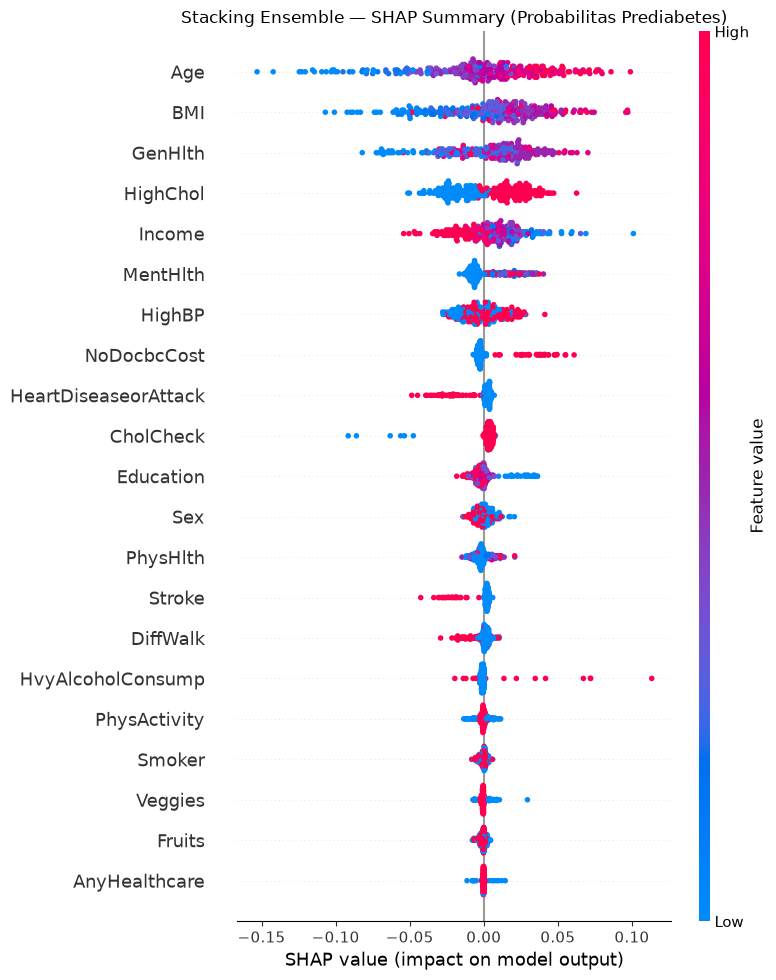

In [11]:
shap.plots.beeswarm(
    stacking_shap_values,
    max_display=21,
    show=False
)
plt.title("Stacking Ensemble — SHAP Summary (Probabilitas Prediabetes)")
plt.tight_layout()
plt.show()

### 8.2 Bar plot

Bar plot mengurutkan fitur berdasarkan rata-rata nilai absolut SHAP. Grafik ini menunjukkan fitur yang paling berpengaruh secara global pada probabilitas Prediabetes, tanpa menunjukkan arah pengaruhnya.

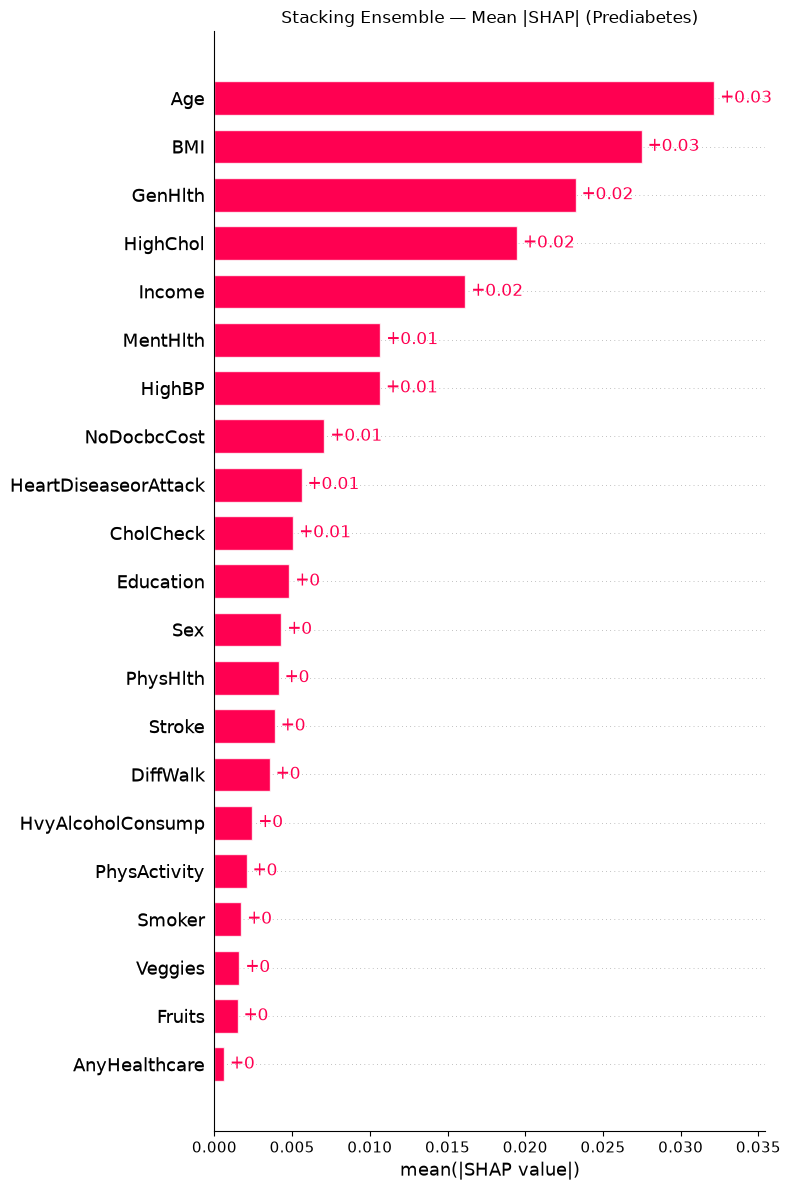

In [12]:
shap.plots.bar(
    stacking_shap_values,
    max_display=21,
    show=False
)
plt.title("Stacking Ensemble — Mean |SHAP| (Prediabetes)")
plt.tight_layout()
plt.show()

### 8.3 Dependence plot untuk fitur teratas

Dependence plot membantu memeriksa hubungan antara nilai suatu fitur dan kontribusi SHAP-nya. Kode memilih tiga fitur teratas berdasarkan rata-rata absolut SHAP. Interpretasi hubungan tetap perlu memperhatikan bahwa asosiasi SHAP tidak membuktikan hubungan sebab-akibat.

Tiga fitur teratas: ['Age', 'BMI', 'GenHlth']


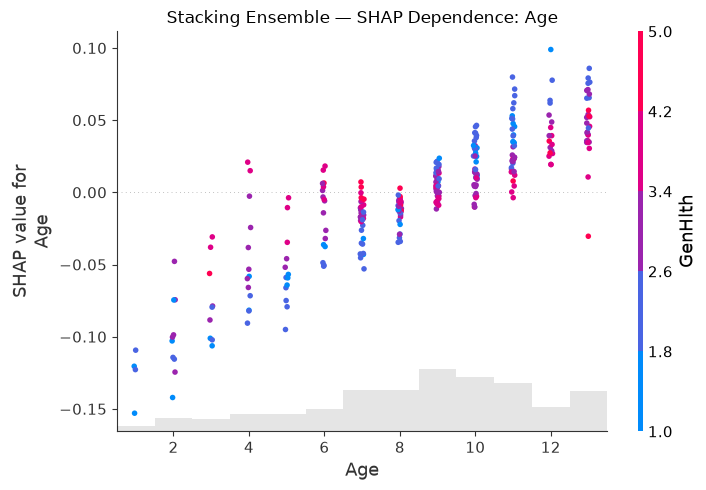

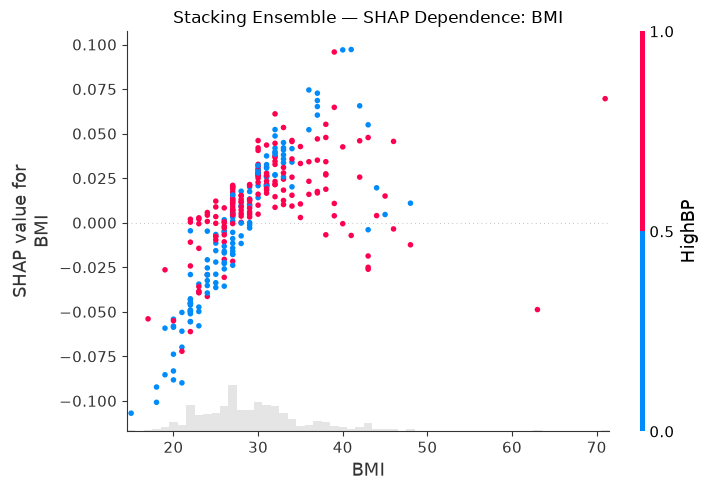

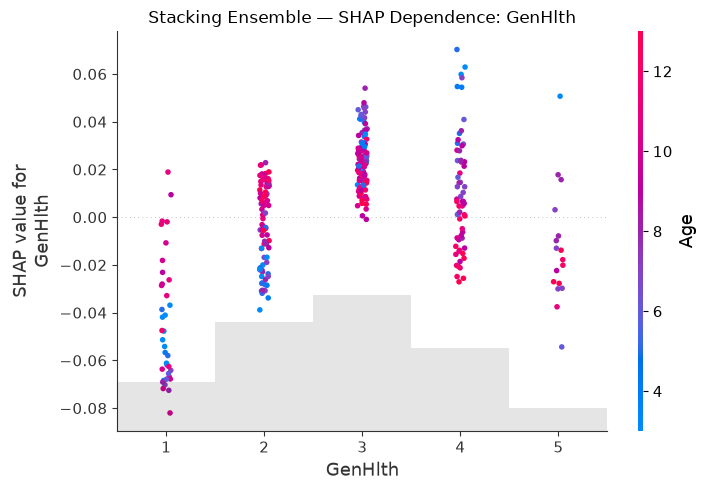

In [13]:
mean_abs_shap = np.abs(stacking_shap_values.values).mean(axis=0)
top_feature_indices = np.argsort(mean_abs_shap)[::-1][:3]
top_features = [feature_names[i] for i in top_feature_indices]

print("Tiga fitur teratas:", top_features)

for feature in top_features:
    shap.plots.scatter(
        stacking_shap_values[:, feature],
        color=stacking_shap_values,
        show=False
    )
    plt.title(f"Stacking Ensemble — SHAP Dependence: {feature}")
    plt.tight_layout()
    plt.show()

## 9. Membuat tabel peringkat fitur

Tabel berikut merangkum rata-rata nilai absolut SHAP dari model Stacking Ensemble. Nilai yang lebih besar menunjukkan kontribusi rata-rata yang lebih besar terhadap probabilitas Prediabetes pada sampel yang dianalisis.

Peringkat ini merupakan ukuran kepentingan model, bukan bukti bahwa fitur menyebabkan diabetes.

In [14]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(stacking_shap_values.values).mean(axis=0),
    "Mean_SHAP": stacking_shap_values.values.mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

importance_df["Rank"] = np.arange(1, len(importance_df) + 1)
importance_df = importance_df[
    ["Rank", "Feature", "Mean_Absolute_SHAP", "Mean_SHAP"]
].reset_index(drop=True)

display(importance_df)

,Rank,Feature,Mean_Absolute_SHAP,Mean_SHAP
0,1,Age,0.032161,-0.001029
1,2,BMI,0.027495,0.004346
2,3,GenHlth,0.023242,0.003027
3,4,HighChol,0.019475,0.002443
4,5,Income,0.016147,0.004845
5,6,MentHlth,0.010679,0.001467
6,7,HighBP,0.010660,-0.000695
7,8,NoDocbcCost,0.007079,0.002209
8,9,HeartDiseaseorAttack,0.005610,-0.001221
9,10,CholCheck,0.005074,0.002417


## 10. Menyimpan hasil analisis

Simpan tabel peringkat fitur dan nilai SHAP agar dapat digunakan untuk dokumentasi penelitian. Folder output terpisah agar artifact model yang sudah ada tidak tertimpa.

In [15]:
OUTPUT_DIR = "artifacts/shap_analysis_v2"
os.makedirs(OUTPUT_DIR, exist_ok=True)

importance_path = os.path.join(
    OUTPUT_DIR,
    "stacking_shap_feature_importance.csv"
)
shap_values_path = os.path.join(
    OUTPUT_DIR,
    "stacking_shap_values.csv"
)

importance_df.to_csv(importance_path, index=False)

shap_values_df = pd.DataFrame(
    stacking_shap_values.values,
    columns=feature_names,
    index=X_explain.index
)
shap_values_df.to_csv(shap_values_path, index=True)

print("Hasil disimpan:")
print(importance_path)
print(shap_values_path)

Hasil disimpan:
artifacts/shap_analysis_v2\stacking_shap_feature_importance.csv
artifacts/shap_analysis_v2\stacking_shap_values.csv


## 11. Panduan interpretasi hasil

Saat menulis hasil penelitian, perhatikan hal-hal berikut:

1. **Gunakan hasil SHAP Stacking Ensemble sebagai interpretasi utama model hybrid.** SHAP RF dan XGBoost hanya menjelaskan masing-masing base learner.
2. **Mean |SHAP|** digunakan untuk mengurutkan kepentingan fitur secara global.
3. **Summary plot** menunjukkan besarnya dan arah kontribusi nilai fitur terhadap probabilitas Prediabetes.
4. **Dependence plot** membantu melihat pola kontribusi fitur, tetapi tidak membuktikan sebab-akibat.
5. Hasil berasal dari sampel data training dan konfigurasi background yang digunakan. Catat ukuran sampel serta `random_state` saat melaporkan hasil.
6. SHAP bukan feature selection secara otomatis. Jika fitur akan dihapus berdasarkan SHAP, keputusan itu harus dibuat sebagai eksperimen terpisah dan dievaluasi ulang tanpa membuka locked test.
7. Pastikan fungsi `stacking_predict_proba` identik dengan alur inferensi di `model/predict.py`. Jika urutan kolom meta-feature atau penanganan threshold berbeda, penjelasan dapat tidak merepresentasikan aplikasi.

**Catatan metodologi:** SHAP menjelaskan perilaku model terhadap data yang diberikan. Hasilnya tidak membuktikan bahwa suatu pola gaya hidup menyebabkan Prediabetes atau Diabetes.